# Machine Learning for Business – CA1
## Metro Interstate Traffic Volume Dataset

In [480]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("Metro_Interstate_Traffic_Volume.csv.gz")

# Display the first five rows
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [481]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (48204, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB

Missing values:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traff

## 2. Data Cleaning and Preprocessing

In this section, I will check the dataset for missing values and duplicate records. I will also prepare the date column for further analysis.

In [482]:
# Check duplicate records
duplicates = df.duplicated().sum()

print("Number of duplicate records:", duplicates)

Number of duplicate records: 17


In [483]:
# Check holiday values
print(df['holiday'].value_counts(dropna=False))

holiday
NaN                          48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64


In [484]:
# Convert date_time to datetime format
df['date_time'] = pd.to_datetime(df['date_time'])

# Check the date range
print("Start date:", df['date_time'].min())
print("End date:", df['date_time'].max())

# Check the updated data type
print("Date column type:", df['date_time'].dtype)

Start date: 2012-10-02 09:00:00
End date: 2018-09-30 23:00:00
Date column type: datetime64[ns]


## 3. Data Cleaning

In this step, I will handle missing values and duplicate records to prepare the dataset for further analysis.

In [485]:
# Replace missing holiday values
df['holiday'] = df['holiday'].fillna('None')

# Check the results
print(df['holiday'].value_counts())

holiday
None                         48143
Labor Day                        7
Thanksgiving Day                 6
Christmas Day                    6
New Years Day                    6
Martin Luther King Jr Day        6
Columbus Day                     5
Veterans Day                     5
Washingtons Birthday             5
Memorial Day                     5
Independence Day                 5
State Fair                       5
Name: count, dtype: int64


In [486]:
# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check dataset dimensions
print("\nFinal dataset shape:", df.shape)

Missing values after cleaning:
holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
traffic_volume         0
dtype: int64

Final dataset shape: (48204, 9)


In [487]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Check the dataset after removing duplicates
print("Dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape: (48187, 9)
Remaining duplicates: 0


In [488]:
# Check repeated timestamps
repeated_dates = df['date_time'].duplicated().sum()

print("Repeated timestamps:", repeated_dates)

Repeated timestamps: 7612


In [489]:
# Final data quality check
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

Dataset shape: (48187, 9)
Missing values: 0
Duplicate records: 0


## 4. Feature Engineering

In this section, I will create new features from the date and time column to better understand traffic patterns during different hours, days and months.

In [490]:
# Extract date and time features
df['hour'] = df['date_time'].dt.hour
df['day_of_week'] = df['date_time'].dt.dayofweek
df['month'] = df['date_time'].dt.month

# Identify weekends
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

# Display the updated dataset
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,hour,day_of_week,month,is_weekend
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,9,1,10,0
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,10,1,10,0
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,11,1,10,0
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,12,1,10,0
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,13,1,10,0


## 5. Clustering Analysis

In this section, I will use clustering to identify different traffic patterns based on traffic volume, weather conditions and time-related features.

In [491]:
# Select numerical features for clustering
clustering_features = [
    'traffic_volume',
    'temp',
    'rain_1h',
    'snow_1h',
    'clouds_all',
    'hour',
    'day_of_week',
    'month'
]

X = df[clustering_features].copy()

# Check selected features
print("Clustering dataset shape:", X.shape)
X.head()

Clustering dataset shape: (48187, 8)


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month
0,5545,288.28,0.0,0.0,40,9,1,10
1,4516,289.36,0.0,0.0,75,10,1,10
2,4767,289.58,0.0,0.0,90,11,1,10
3,5026,290.13,0.0,0.0,90,12,1,10
4,4918,291.14,0.0,0.0,75,13,1,10


In [492]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardise clustering features
X_scaled = scaler.fit_transform(X)

# Check the result
print("Scaled dataset shape:", X_scaled.shape)
print("First five rows:")
print(X_scaled[:5])

Scaled dataset shape: (48187, 8)
First five rows:
[[ 1.15020531  0.53041592 -0.00746445 -0.02723315 -0.24004863 -0.34548099
  -0.98947829  1.02779521]
 [ 0.63232194  0.61138394 -0.00746445 -0.02723315  0.65704665 -0.20139502
  -0.98947829  1.02779521]
 [ 0.75864723  0.62787742 -0.00746445 -0.02723315  1.04151605 -0.05730906
  -0.98947829  1.02779521]
 [ 0.88899883  0.66911114 -0.00746445 -0.02723315  1.04151605  0.08677691
  -0.98947829  1.02779521]
 [ 0.83464372  0.74483123 -0.00746445 -0.02723315  0.65704665  0.23086287
  -0.98947829  1.02779521]]


In [493]:
# Check for possible outliers in clustering features

X.describe().round(2)

,traffic_volume,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month
count,48187.00,48187.00,48187.00,48187.00,48187.00,48187.00,48187.00,48187.00
mean,3259.62,281.20,0.33,0.00,49.37,11.40,2.98,6.51
std,1986.95,13.34,44.80,0.01,39.02,6.94,2.01,3.40
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
25%,1192.50,272.16,0.00,0.00,1.00,5.00,1.00,4.00
50%,3379.00,282.45,0.00,0.00,64.00,11.00,3.00,7.00
75%,4933.00,291.81,0.00,0.00,90.00,17.00,5.00,9.00
max,7280.00,310.07,9831.30,0.51,100.00,23.00,6.00,12.00


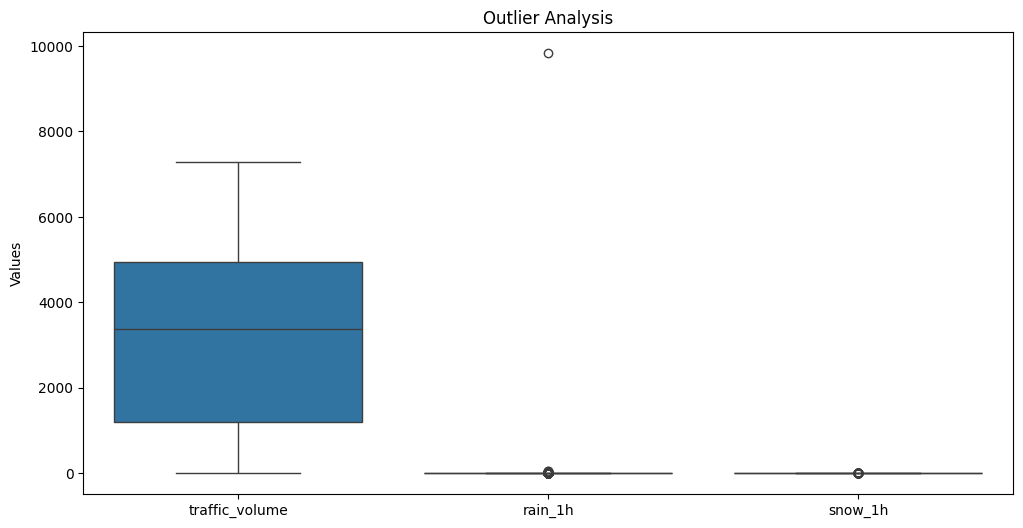

In [494]:
# Visualise possible outliers

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(data=X[['traffic_volume', 'rain_1h', 'snow_1h']])

plt.title('Outlier Analysis')
plt.ylabel('Values')
plt.show()

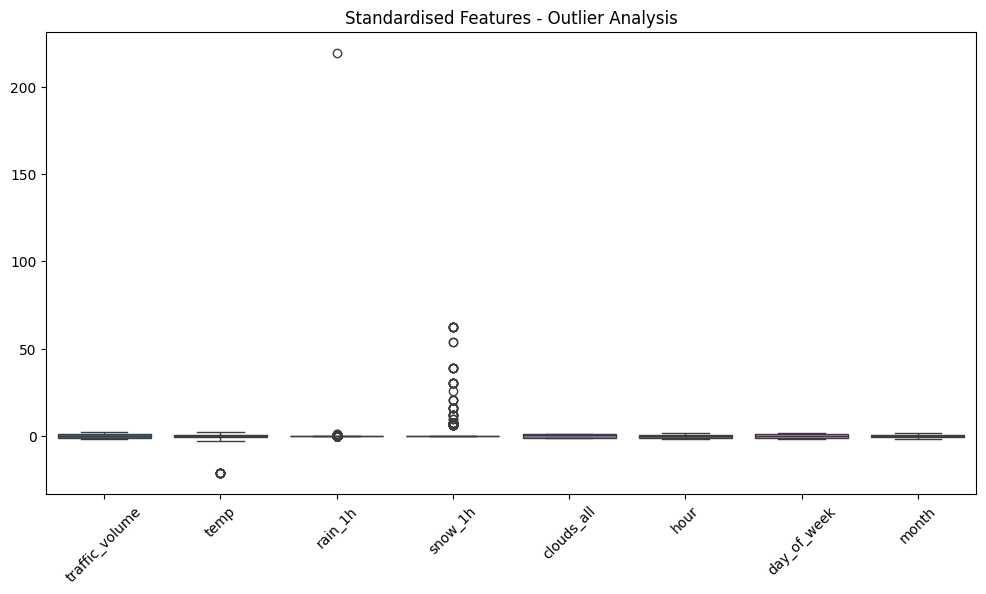

In [495]:
# Compare standardised features

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features
)

plt.figure(figsize=(12, 6))

sns.boxplot(data=X_scaled_df)

plt.title('Standardised Features - Outlier Analysis')
plt.xticks(rotation=45)
plt.show()

In [496]:
# Check extreme values in weather variables

weather_features = ['temp', 'rain_1h', 'snow_1h']

for feature in weather_features:
    print(f"\nFeature: {feature}")
    print("Minimum:", df[feature].min())
    print("Maximum:", df[feature].max())
    print("99th percentile:", df[feature].quantile(0.99))


Feature: temp
Minimum: 0.0
Maximum: 310.07
99th percentile: 302.8228

Feature: rain_1h
Minimum: 0.0
Maximum: 9831.3
99th percentile: 3.271399999999994

Feature: snow_1h
Minimum: 0.0
Maximum: 0.51
99th percentile: 0.0


In [497]:
# Check suspicious weather values

print("Temperature equal to zero:", (df['temp'] == 0).sum())

print("Rain above 100 mm:", (df['rain_1h'] > 100).sum())

print("Snow above zero:", (df['snow_1h'] > 0).sum())

Temperature equal to zero: 10
Rain above 100 mm: 1
Snow above zero: 63


### 5.1 Handling Outliers

I found some unusual values in the weather data, including zero temperatures and very high rainfall. I will treat these values before applying clustering.

In [498]:
# Create a copy for clustering
df_clustering = df.copy()

# Replace invalid temperatures with missing values
df_clustering.loc[df_clustering['temp'] == 0, 'temp'] = float('nan')

# Replace the suspicious rainfall value
df_clustering.loc[df_clustering['rain_1h'] > 100, 'rain_1h'] = float('nan')

# Fill missing values using the median
df_clustering['temp'] = df_clustering['temp'].fillna(
    df_clustering['temp'].median()
)

df_clustering['rain_1h'] = df_clustering['rain_1h'].fillna(
    df_clustering['rain_1h'].median()
)

# Check the results
print("Missing values:", df_clustering.isnull().sum().sum())
print("Minimum temperature:", df_clustering['temp'].min())
print("Maximum rainfall:", df_clustering['rain_1h'].max())

Missing values: 0
Minimum temperature: 243.39
Maximum rainfall: 55.63


In [499]:
# Select the cleaned features for clustering
X = df_clustering[clustering_features].copy()

# Standardise the cleaned data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check the results
print("Clustering dataset shape:", X.shape)
print("Scaled dataset shape:", X_scaled.shape)
print("Missing values:", X.isnull().sum().sum())

Clustering dataset shape: (48187, 8)
Scaled dataset shape: (48187, 8)
Missing values: 0


In [500]:
# Check standardised features

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features
)

print("Feature means:")
print(X_scaled_df.mean().round(2))

print("\nFeature standard deviations:")
print(X_scaled_df.std(ddof=0).round(2))

Feature means:
traffic_volume   -0.0
temp             -0.0
rain_1h          -0.0
snow_1h           0.0
clouds_all        0.0
hour             -0.0
day_of_week       0.0
month            -0.0
dtype: float64

Feature standard deviations:
traffic_volume    1.0
temp              1.0
rain_1h           1.0
snow_1h           1.0
clouds_all        1.0
hour              1.0
day_of_week       1.0
month             1.0
dtype: float64


### 5.2 K-Means Clustering

In this section, I will use K-Means to identify groups with similar traffic patterns. I will test different numbers of clusters to find a suitable value of K.

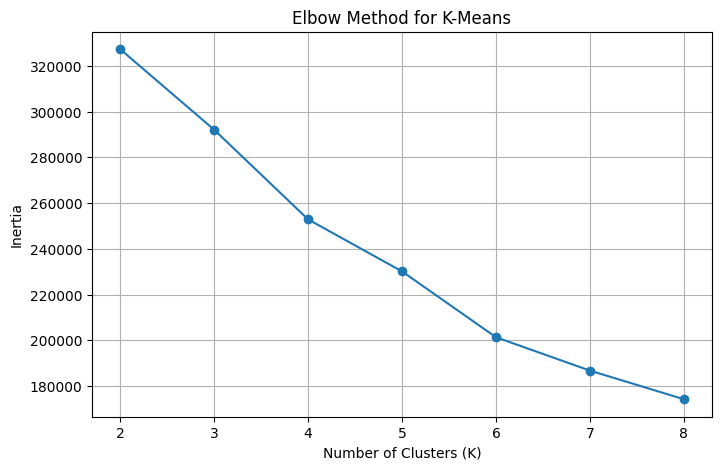

In [501]:
# Import K-Means
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Test different numbers of clusters
inertia_values = []

k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia_values, marker='o')

plt.title('Elbow Method for K-Means')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [502]:
# Evaluate different numbers of clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in [3, 4, 5]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=5000,
        random_state=42
    )

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 3, Silhouette Score = 0.1966
K = 4, Silhouette Score = 0.1966
K = 5, Silhouette Score = 0.1932


In [503]:
# Apply K-Means with 4 clusters

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit the model
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to the cleaned dataset
df_clustering['cluster'] = cluster_labels

# Check the number of records in each cluster
print("Number of records per cluster:")
print(df_clustering['cluster'].value_counts().sort_index())

Number of records per cluster:
cluster
0    11342
1    23277
2    13545
3       23
Name: count, dtype: int64


In [504]:
# Check average values for each cluster

cluster_summary = df_clustering.groupby('cluster')[
    clustering_features
].mean().round(2)

print("Average feature values by cluster:")
display(cluster_summary)

Average feature values by cluster:


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month
cluster,,,,,,,,
0,4062.82,270.38,0.03,0.00,58.87,14.24,2.83,2.51
1,4266.15,287.55,0.16,0.00,48.26,14.87,2.85,8.31
2,857.38,279.60,0.16,0.00,43.25,3.04,3.35,6.74
3,3224.87,271.86,0.17,0.34,90.00,14.52,2.04,8.65


### 5.3 K-Means Cluster Evaluation

In this section, I will analyse the K-Means results to better understand the differences between the clusters and evaluate the model.

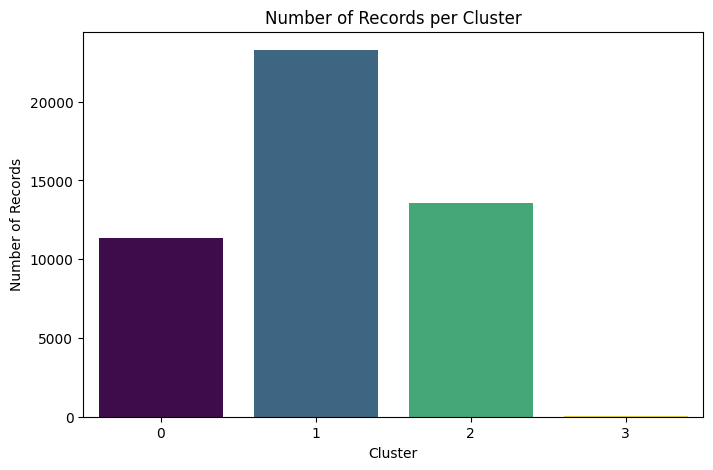

In [505]:
# Visualise the number of records in each cluster

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clustering,
    x='cluster',
    hue='cluster',
    palette='viridis',
    legend=False
)

plt.title('Number of Records per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Records')

plt.show()

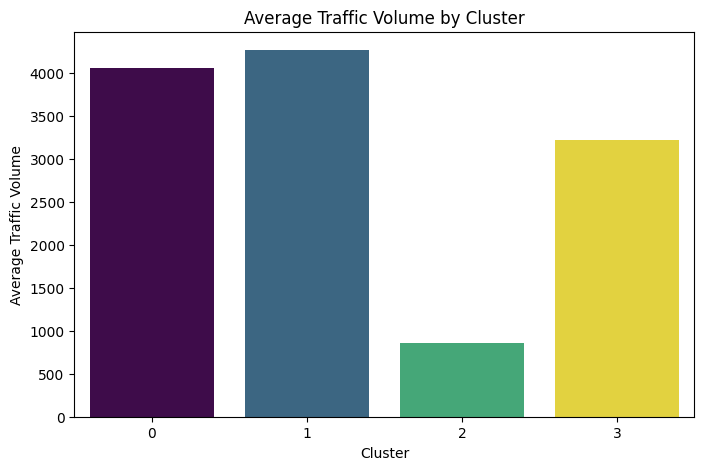

In [506]:
# Compare average traffic volume by cluster

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clustering,
    x='cluster',
    y='traffic_volume',
    hue='cluster',
    palette='viridis',
    legend=False,
    errorbar=None
)

plt.title('Average Traffic Volume by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Traffic Volume')

plt.show()

In [507]:
# Analyse the small cluster

cluster_3 = df_clustering[df_clustering['cluster'] == 3]

print("Number of records:", len(cluster_3))

print("\nWeather conditions:")
print(cluster_3['weather_main'].value_counts())

print("\nAverage snowfall:")
print(cluster_3['snow_1h'].mean())

print("\nAverage traffic volume:")
print(cluster_3['traffic_volume'].mean())

Number of records: 23

Weather conditions:
weather_main
Snow    10
Mist     9
Rain     3
Fog      1
Name: count, dtype: int64

Average snowfall:
0.3373913043478261

Average traffic volume:
3224.8695652173915


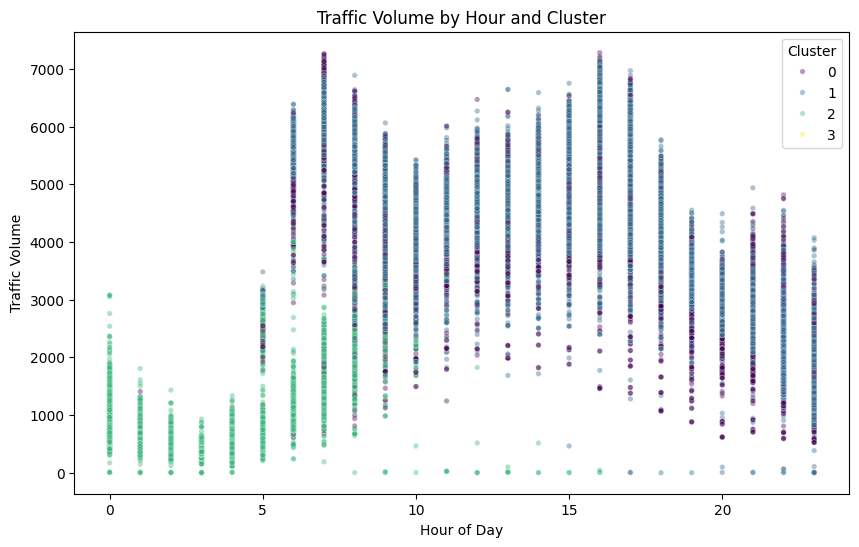

In [508]:
# Visualise traffic patterns by cluster

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clustering,
    x='hour',
    y='traffic_volume',
    hue='cluster',
    palette='viridis',
    alpha=0.4,
    s=15
)

plt.title('Traffic Volume by Hour and Cluster')
plt.xlabel('Hour of Day')
plt.ylabel('Traffic Volume')
plt.legend(title='Cluster')

plt.show()

### 5.4 K-Means Evaluation

The K-Means model identified four clusters with different
traffic patterns.

The Silhouette Score was approximately 0.20, suggesting
that the clusters are not clearly separated.

One cluster contained only 23 records and showed higher
snowfall values. This suggests that unusual weather
conditions may have influenced the clustering results.

The model provides an initial view of traffic patterns,
but further evaluation is needed.

In [509]:
# Final K-Means evaluation summary

print("Total records:", len(df_clustering))
print("Number of clusters:", df_clustering['cluster'].nunique())

print("\nCluster distribution (%):")
print(
    (df_clustering['cluster'].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

print("\nAverage traffic volume by cluster:")
print(
    df_clustering.groupby('cluster')['traffic_volume']
    .mean()
    .round(2)
)

Total records: 48187
Number of clusters: 4

Cluster distribution (%):
cluster
0    23.54
1    48.31
2    28.11
3     0.05
Name: proportion, dtype: float64

Average traffic volume by cluster:
cluster
0    4062.82
1    4266.15
2     857.38
3    3224.87
Name: traffic_volume, dtype: float64


### 5.5 Hierarchical Clustering

In this section, I will test hierarchical clustering to identify traffic patterns and compare the results with K-Means.

In [510]:
# Prepare a sample for hierarchical clustering

import numpy as np

np.random.seed(42)

sample_indices = np.random.choice(
    len(X_scaled),
    size=3000,
    replace=False
)

X_sample = X_scaled[sample_indices]

print("Sample shape:", X_sample.shape)

Sample shape: (3000, 8)


In [511]:
# Apply hierarchical clustering

from sklearn.cluster import AgglomerativeClustering

hierarchical_model = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hierarchical_labels = hierarchical_model.fit_predict(X_sample)

print("Hierarchical clustering results:")

print(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
)

Hierarchical clustering results:
0    2117
1      48
2       1
3     834
Name: count, dtype: int64


In [512]:
# Evaluate hierarchical clustering

from sklearn.metrics import silhouette_score

hierarchical_score = silhouette_score(
    X_sample,
    hierarchical_labels
)

print(
    "Hierarchical Silhouette Score:",
    round(hierarchical_score, 4)
)

Hierarchical Silhouette Score: 0.2175


In [513]:
# Compare K-Means using the same sample

from sklearn.cluster import KMeans

kmeans_sample = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_sample_labels = kmeans_sample.fit_predict(X_sample)

kmeans_sample_score = silhouette_score(
    X_sample,
    kmeans_sample_labels
)

print("K-Means Silhouette Score:", round(kmeans_sample_score, 4))
print("Hierarchical Silhouette Score:", round(hierarchical_score, 4))

K-Means Silhouette Score: 0.2077
Hierarchical Silhouette Score: 0.2175


### 5.6 Comparison of Clustering Models

In this section, I will compare K-Means and Hierarchical Clustering using the same sample of traffic data.

In [514]:
# Compare cluster sizes between the two models

comparison_df = pd.DataFrame({
    'K-Means': pd.Series(kmeans_sample_labels).value_counts().sort_index(),
    'Hierarchical': pd.Series(hierarchical_labels).value_counts().sort_index()
})

print("Cluster distribution comparison:")
display(comparison_df)

Cluster distribution comparison:


,K-Means,Hierarchical
0,832,2117
1,714,48
2,1442,1
3,12,834


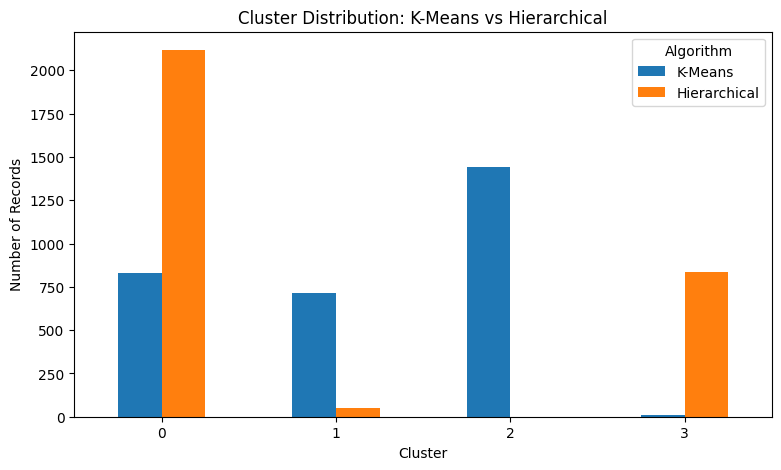

In [515]:
# Compare cluster distributions visually

comparison_df.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Cluster Distribution: K-Means vs Hierarchical')
plt.xlabel('Cluster')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.legend(title='Algorithm')
plt.show()

In [516]:
# Compare agreement between clustering models

from sklearn.metrics import adjusted_rand_score

ari_score = adjusted_rand_score(
    kmeans_sample_labels,
    hierarchical_labels
)

print("Adjusted Rand Index:", round(ari_score, 4))

Adjusted Rand Index: 0.5171


In [517]:
# Calculate Davies-Bouldin Index for both clustering models

from sklearn.metrics import davies_bouldin_score

kmeans_db = davies_bouldin_score(
    X_sample,
    kmeans_sample_labels
)

hierarchical_db = davies_bouldin_score(
    X_sample,
    hierarchical_labels
)

print("K-Means Davies-Bouldin Index:", round(kmeans_db, 4))
print("Hierarchical Davies-Bouldin Index:", round(hierarchical_db, 4))

K-Means Davies-Bouldin Index: 1.4301
Hierarchical Davies-Bouldin Index: 1.1313


In [518]:
# Final comparison of clustering models

model_comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical'],
    'Silhouette Score': [
        round(kmeans_sample_score, 4),
        round(hierarchical_score, 4)
    ],
    'Davies-Bouldin Index': [
        round(kmeans_db, 4),
        round(hierarchical_db, 4)
    ],
    'Number of Clusters': [4, 4],
    'Sample Size': [3000, 3000]
})

display(model_comparison)

,Algorithm,Silhouette Score,Davies-Bouldin Index,Number of Clusters,Sample Size
0,K-Means,0.2077,1.4301,4,3000
1,Hierarchical,0.2175,1.1313,4,3000


### 5.7 Clustering Comparison Summary


I compared K-Means and Hierarchical Clustering using the same sample of 3,000 traffic records.

K-Means achieved a Silhouette Score of 0.2077, while Hierarchical Clustering achieved 0.2175.

Hierarchical Clustering had a slightly higher score, but it also created a cluster with only one record.

Both models showed relatively low Silhouette Scores, which suggests that the clusters were not clearly separated.

The results helped me identify different traffic patterns, but the clustering models still have some limitations.

In [519]:
# Final clustering comparison

print("K-Means Silhouette Score:", round(kmeans_sample_score, 4))
print("Hierarchical Silhouette Score:", round(hierarchical_score, 4))
print("Adjusted Rand Index:", round(ari_score, 4))

print("\nK-Means cluster sizes:")
print(pd.Series(kmeans_sample_labels).value_counts().sort_index())

print("\nHierarchical cluster sizes:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

K-Means Silhouette Score: 0.2077
Hierarchical Silhouette Score: 0.2175
Adjusted Rand Index: 0.5171

K-Means cluster sizes:
0     832
1     714
2    1442
3      12
Name: count, dtype: int64

Hierarchical cluster sizes:
0    2117
1      48
2       1
3     834
Name: count, dtype: int64


The Adjusted Rand Index was 0.5171, showing moderate agreement between the two clustering models.

## 6. Time Series Analysis

In this section, I will analyse traffic volume over time and prepare the data for forecasting models such as ARIMA and SARIMA.

In [520]:
# Prepare traffic volume data for time series analysis

traffic_ts = df.copy()

# Convert date column to datetime
traffic_ts['date_time'] = pd.to_datetime(traffic_ts['date_time'])

# Sort the data by date
traffic_ts = traffic_ts.sort_values('date_time')

print("Dataset shape:", traffic_ts.shape)
print("Date range:", traffic_ts['date_time'].min(), "to", traffic_ts['date_time'].max())

display(traffic_ts[['date_time', 'traffic_volume']].head())

Dataset shape: (48187, 13)
Date range: 2012-10-02 09:00:00 to 2018-09-30 23:00:00


,date_time,traffic_volume
0,2012-10-02 09:00:00,5545
1,2012-10-02 10:00:00,4516
2,2012-10-02 11:00:00,4767
3,2012-10-02 12:00:00,5026
4,2012-10-02 13:00:00,4918


In [521]:
# Check duplicate timestamps

duplicate_dates = traffic_ts['date_time'].duplicated().sum()

print("Total records:", len(traffic_ts))
print("Duplicate timestamps:", duplicate_dates)
print("Unique timestamps:", traffic_ts['date_time'].nunique())

Total records: 48187
Duplicate timestamps: 7612
Unique timestamps: 40575


In [522]:
# Investigate traffic volume differences at repeated timestamps

duplicate_summary = (
    traffic_ts.groupby('date_time')['traffic_volume']
    .agg(['count', 'min', 'max', 'mean'])
)

duplicate_summary = duplicate_summary[
    duplicate_summary['count'] > 1
]

print("Timestamps with multiple records:", len(duplicate_summary))

print(
    "Timestamps with different traffic volumes:",
    (duplicate_summary['min'] != duplicate_summary['max']).sum()
)

display(duplicate_summary.head(10))

Timestamps with multiple records: 5430
Timestamps with different traffic volumes: 0


,count,min,max,mean
date_time,,,,
2012-10-10 07:00:00,2,6793,6793,6793.0
2012-10-10 08:00:00,2,6283,6283,6283.0
2012-10-10 09:00:00,2,5680,5680,5680.0
2012-10-14 09:00:00,3,2685,2685,2685.0
2012-10-14 10:00:00,2,3370,3370,3370.0
2012-10-14 11:00:00,2,3662,3662,3662.0
2012-10-14 12:00:00,3,4076,4076,4076.0
2012-10-14 13:00:00,3,4128,4128,4128.0
2012-10-14 14:00:00,3,4358,4358,4358.0


In [523]:
# Aggregate traffic volume by timestamp

hourly_traffic = (
    traffic_ts.groupby('date_time')['traffic_volume']
    .mean()
    .sort_index()
)

print("Number of unique hourly observations:", len(hourly_traffic))

display(hourly_traffic.head(10))

Number of unique hourly observations: 40575


date_time
2012-10-02 09:00:00    5545.0
2012-10-02 10:00:00    4516.0
2012-10-02 11:00:00    4767.0
2012-10-02 12:00:00    5026.0
2012-10-02 13:00:00    4918.0
2012-10-02 14:00:00    5181.0
2012-10-02 15:00:00    5584.0
2012-10-02 16:00:00    6015.0
2012-10-02 17:00:00    5791.0
2012-10-02 18:00:00    4770.0
Name: traffic_volume, dtype: float64

In [524]:
# Check missing hours in the time series

hourly_traffic = hourly_traffic.asfreq('h')

print("Total expected hourly observations:", len(hourly_traffic))
print("Missing hourly observations:", hourly_traffic.isna().sum())

print(
    "Missing percentage:",
    round(hourly_traffic.isna().mean() * 100, 2),
    "%"
)

Total expected hourly observations: 52551
Missing hourly observations: 11976
Missing percentage: 22.79 %


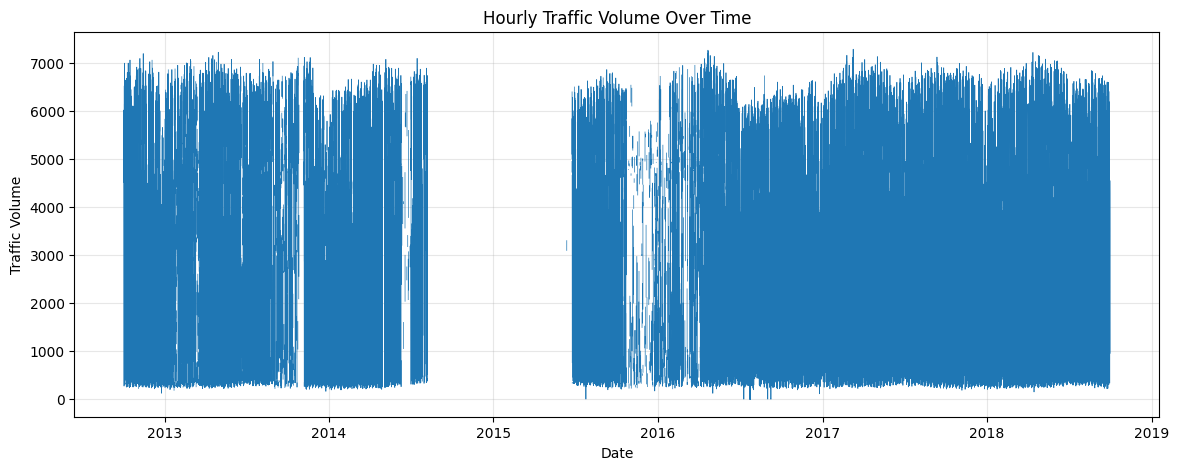

In [525]:
# Visualise hourly traffic volume

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(hourly_traffic, linewidth=0.5)

plt.title('Hourly Traffic Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Traffic Volume')

plt.grid(alpha=0.3)
plt.show()

In [526]:
# Check daily data coverage

daily_coverage = hourly_traffic.resample('D').count()

print("Total days:", len(daily_coverage))
print("Days without observations:", (daily_coverage == 0).sum())

print("Days with 24 observations:", (daily_coverage == 24).sum())

print("Average observations per day:", round(daily_coverage.mean(), 2))

Total days: 2190
Days without observations: 330
Days with 24 observations: 1214
Average observations per day: 18.53


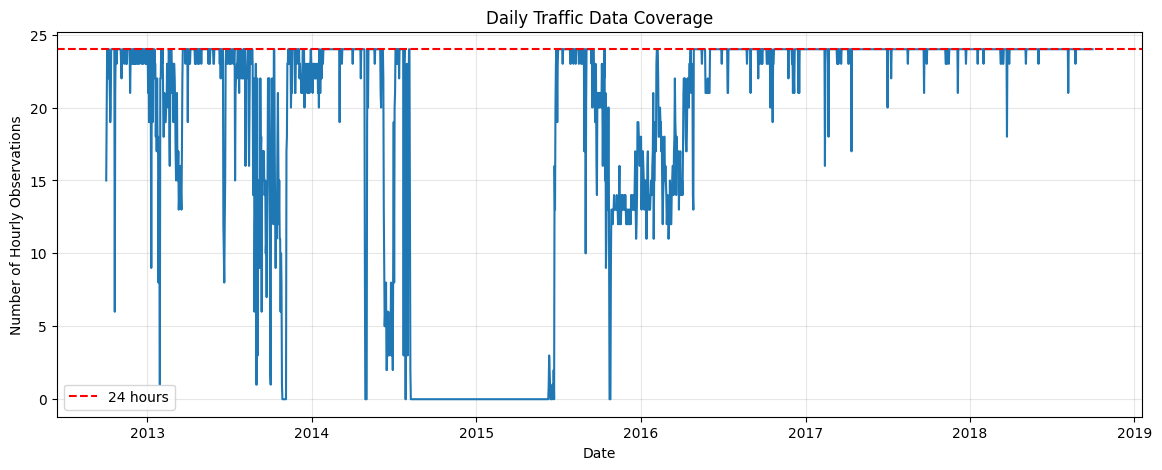

In [527]:
# Visualise daily data coverage

plt.figure(figsize=(14, 5))

plt.plot(daily_coverage)

plt.title('Daily Traffic Data Coverage')
plt.xlabel('Date')
plt.ylabel('Number of Hourly Observations')

plt.axhline(
    y=24,
    color='red',
    linestyle='--',
    label='24 hours'
)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [528]:
# Calculate average daily traffic volume

daily_traffic = hourly_traffic.resample('D').mean()

print("Total daily observations:", len(daily_traffic))

print("Days with missing traffic values:", daily_traffic.isna().sum())

display(daily_traffic.head(10))

Total daily observations: 2190
Days with missing traffic values: 330


date_time
2012-10-02    4219.266667
2012-10-03    3317.250000
2012-10-04    3747.458333
2012-10-05    4242.545455
2012-10-06    3256.956522
2012-10-07    3058.636364
2012-10-08    3422.291667
2012-10-09    3770.304348
2012-10-10    3785.523810
2012-10-11    3911.842105
Freq: D, Name: traffic_volume, dtype: float64

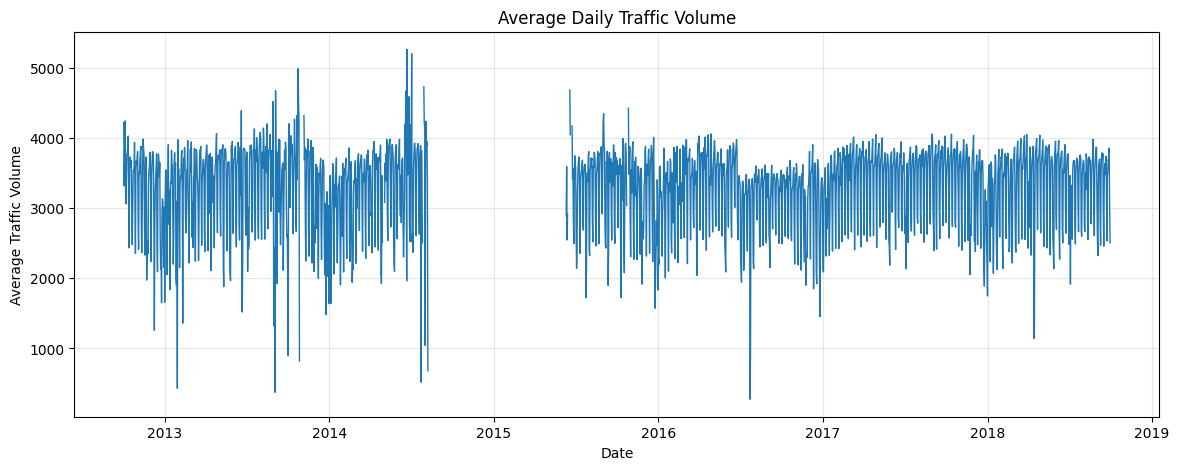

In [529]:
# Visualise average daily traffic volume

plt.figure(figsize=(14, 5))

plt.plot(
    daily_traffic,
    linewidth=1
)

plt.title('Average Daily Traffic Volume')
plt.xlabel('Date')
plt.ylabel('Average Traffic Volume')

plt.grid(alpha=0.3)
plt.show()

In [530]:
# Check daily traffic data quality

print("Total days:", len(daily_traffic))
print("Days without observations:", daily_traffic.isna().sum())

print("\nDaily coverage summary:")
print(daily_coverage.describe())

print("\nDays with fewer than 12 hourly observations:")
print((daily_coverage < 12).sum())

Total days: 2190
Days without observations: 330

Daily coverage summary:
count    2190.000000
mean       18.527397
std         8.805130
min         0.000000
25%        16.000000
50%        24.000000
75%        24.000000
max        24.000000
Name: traffic_volume, dtype: float64

Days with fewer than 12 hourly observations:
398


In [531]:
# Identify consecutive days without traffic observations

missing_days = daily_traffic.isna()

missing_groups = missing_days.ne(missing_days.shift()).cumsum()

missing_periods = (
    missing_days.groupby(missing_groups)
    .sum()
)

missing_periods = missing_periods[missing_periods > 0]

print("Number of missing periods:", len(missing_periods))

if len(missing_periods) > 0:
    print("Longest period without data:", missing_periods.max(), "days")
else:
    print("No missing days found.")

Number of missing periods: 8
Longest period without data: 306 days


In [532]:
# Analyse data coverage by year

yearly_coverage = pd.DataFrame({
    'Total Days': daily_coverage.resample('YE').size(),
    'Days With Data': daily_coverage.gt(0).resample('YE').sum(),
    'Complete Days': daily_coverage.eq(24).resample('YE').sum()
})

yearly_coverage['Coverage (%)'] = (
    yearly_coverage['Days With Data']
    / yearly_coverage['Total Days']
    * 100
).round(2)

display(yearly_coverage)

,Total Days,Days With Data,Complete Days,Coverage (%)
date_time,,,,
2012-12-31,91,91,54,100.00
2013-12-31,365,356,135,97.53
2014-12-31,365,214,140,58.63
2015-12-31,365,195,68,53.42
2016-12-31,366,366,212,100.00
2017-12-31,365,365,344,100.00
2018-12-31,273,273,261,100.00


In [533]:
# Select the period from 2016 onwards

daily_traffic_selected = daily_traffic.loc['2016-01-01':'2018-09-30'].copy()

print("Selected observations:", len(daily_traffic_selected))
print("Missing days:", daily_traffic_selected.isna().sum())

print("Start date:", daily_traffic_selected.index.min())
print("End date:", daily_traffic_selected.index.max())

Selected observations: 1004
Missing days: 0
Start date: 2016-01-01 00:00:00
End date: 2018-09-30 00:00:00


In [534]:
# Check data coverage in the selected period

selected_coverage = daily_coverage.loc[
    daily_traffic_selected.index.min():daily_traffic_selected.index.max()
]

print("Total days:", len(selected_coverage))
print("Days with 24 hours:", (selected_coverage == 24).sum())
print("Days with fewer than 12 hours:", (selected_coverage < 12).sum())

print("\nAverage hourly observations per day:")
print(round(selected_coverage.mean(), 2))

Total days: 1004
Days with 24 hours: 817
Days with fewer than 12 hours: 3

Average hourly observations per day:
22.99


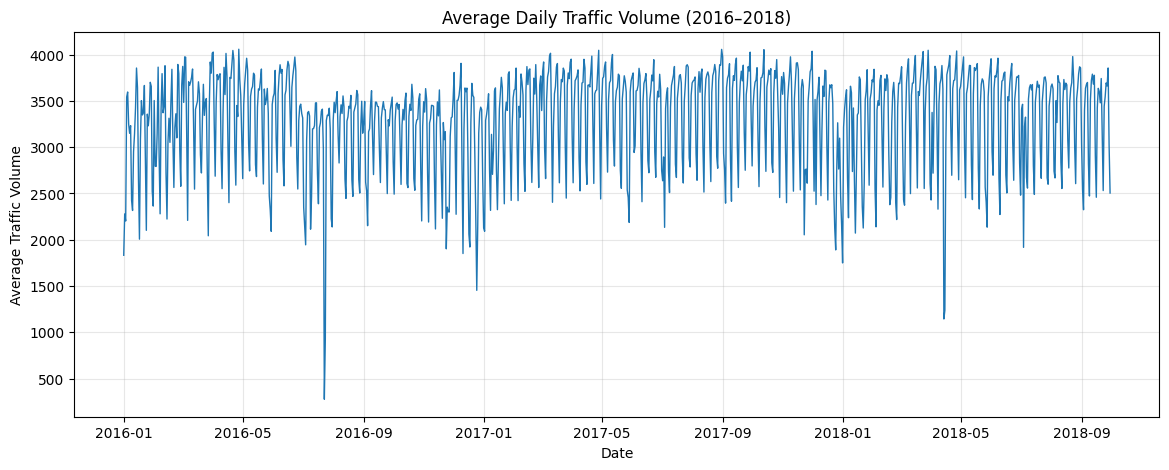

In [535]:
# Plot selected daily traffic series

plt.figure(figsize=(14, 5))

plt.plot(daily_traffic_selected, linewidth=1)

plt.title('Average Daily Traffic Volume (2016–2018)')
plt.xlabel('Date')
plt.ylabel('Average Traffic Volume')

plt.grid(alpha=0.3)
plt.show()

In [536]:
# Final time series validation

print("Frequency:", daily_traffic_selected.index.freq)
print("Missing values:", daily_traffic_selected.isna().sum())
print("Duplicate dates:", daily_traffic_selected.index.duplicated().sum())

print("\nTraffic volume statistics:")
print(daily_traffic_selected.describe())

Frequency: <Day>
Missing values: 0
Duplicate dates: 0

Traffic volume statistics:
count    1004.000000
mean     3298.102050
std       540.777284
min       277.250000
25%      2937.056548
50%      3479.812500
75%      3711.937500
max      4057.384615
Name: traffic_volume, dtype: float64


### 6.1 Time Series Data Preparation

I converted the hourly traffic data into daily averages.

I found that 2014 and 2015 had many missing days. For this reason, I selected the period from 2016 to 2018 for forecasting.

This period has observations for every day, which makes it more suitable for ARIMA and SARIMA models.

However, some days have fewer than 24 hourly observations, which is a limitation of the daily averages.

In [537]:
# Investigate days with unusually low traffic volume

low_traffic_days = daily_traffic_selected[
    daily_traffic_selected < 1000
]

print("Days with average traffic below 1000:", len(low_traffic_days))

display(low_traffic_days)

print("\nHourly coverage for these days:")

display(selected_coverage.loc[low_traffic_days.index])

Days with average traffic below 1000: 2


date_time
2016-07-23    277.250000
2016-07-24    927.958333
Freq: D, Name: traffic_volume, dtype: float64


Hourly coverage for these days:


date_time
2016-07-23    24
2016-07-24    24
Freq: D, Name: traffic_volume, dtype: int64

In [538]:
# Check hourly coverage in the selected period

print("Days with 24 observations:",
      (selected_coverage == 24).sum())

print("Days with fewer than 20 observations:",
      (selected_coverage < 20).sum())

print("Days with fewer than 12 observations:",
      (selected_coverage < 12).sum())

print("Minimum hourly observations in one day:",
      selected_coverage.min())

Days with 24 observations: 817
Days with fewer than 20 observations: 98
Days with fewer than 12 observations: 3
Minimum hourly observations in one day: 11


In [539]:
# Compare daily traffic volume with hourly data coverage

coverage_comparison = pd.DataFrame({
    'Average Traffic': daily_traffic_selected,
    'Hours Available': selected_coverage
})

display(
    coverage_comparison.sort_values('Hours Available').head(15)
)

,Average Traffic,Hours Available
date_time,,
2016-01-30,2522.727273,11
2016-03-03,3975.181818,11
2016-01-14,3854.181818,11
2016-03-04,3970.500000,12
2016-03-09,3701.583333,12
2016-02-28,2577.083333,12
2016-03-05,3169.083333,12
2016-03-08,3666.833333,12
2016-02-19,3840.416667,12


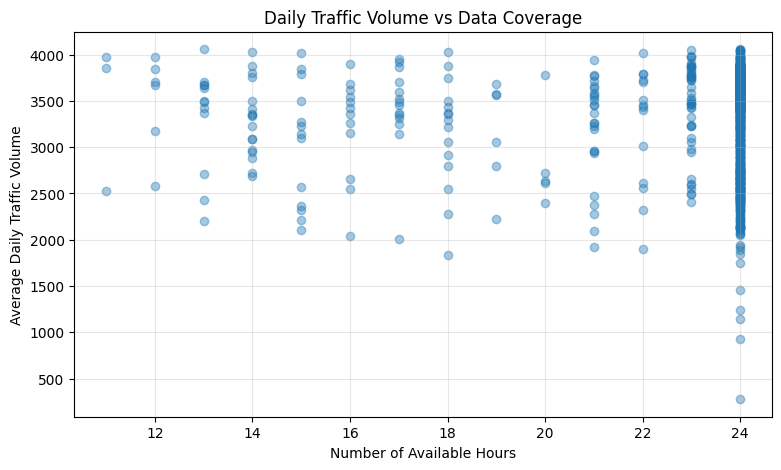

In [540]:
# Check the relationship between daily traffic and data coverage

plt.figure(figsize=(9, 5))

plt.scatter(
    coverage_comparison['Hours Available'],
    coverage_comparison['Average Traffic'],
    alpha=0.4
)

plt.title('Daily Traffic Volume vs Data Coverage')
plt.xlabel('Number of Available Hours')
plt.ylabel('Average Daily Traffic Volume')

plt.grid(alpha=0.3)
plt.show()

In [541]:
# Compare average traffic on complete and incomplete days

complete_days = coverage_comparison[
    coverage_comparison['Hours Available'] == 24
]

incomplete_days = coverage_comparison[
    coverage_comparison['Hours Available'] < 24
]

print("Average traffic on complete days:",
      round(complete_days['Average Traffic'].mean(), 2))

print("Average traffic on incomplete days:",
      round(incomplete_days['Average Traffic'].mean(), 2))

Average traffic on complete days: 3302.09
Average traffic on incomplete days: 3280.66


### 6.2 Data Quality and Limitations

The selected time series contains 1,004 daily observations from 2016 to 2018.

There are no missing days or duplicate dates. However, some days have fewer than 24 hourly observations.

I decided to keep the daily averages for the initial forecasting models, but this is a limitation because incomplete days may not represent the full daily traffic pattern.

### 6.3 Final Time Series Preparation

I selected the period from 2016 to 2018 because it has better daily data coverage.

The final dataset contains 1,004 daily observations, with no missing dates or duplicate timestamps.

I also compared the average traffic volume between complete and incomplete days.

Complete days had an average traffic volume of 3302.09, while incomplete days had an average of 3280.66.

The difference was small, so I decided to keep the daily observations for the forecasting models.

However, some days have fewer than 24 hourly records, which may affect the accuracy of the daily averages.

## 7. ARIMA Forecasting

In this section, I will use ARIMA to predict daily traffic volume.

I will split the data into training and testing sets, check stationarity and evaluate the predictions.

In [542]:
# Split the data into training and testing sets

train_size = int(len(daily_traffic_selected) * 0.8)

train = daily_traffic_selected.iloc[:train_size]
test = daily_traffic_selected.iloc[train_size:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training observations: 803
Testing observations: 201
Training period: 2016-01-01 00:00:00 to 2018-03-13 00:00:00
Testing period: 2018-03-14 00:00:00 to 2018-09-30 00:00:00


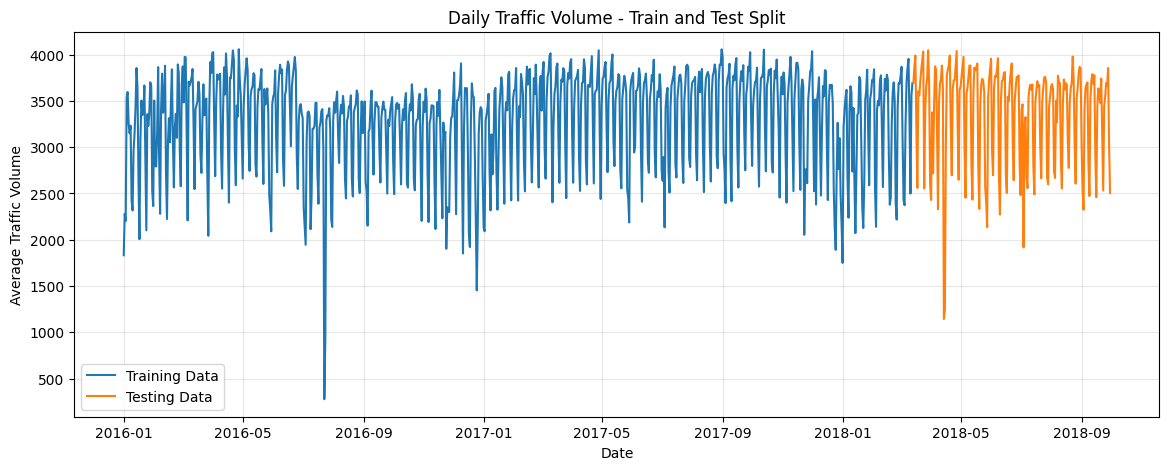

In [543]:
# Visualise training and testing data

plt.figure(figsize=(14, 5))

plt.plot(train, label='Training Data')
plt.plot(test, label='Testing Data')

plt.title('Daily Traffic Volume - Train and Test Split')
plt.xlabel('Date')
plt.ylabel('Average Traffic Volume')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [544]:
# Check stationarity using the ADF test

from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train.dropna())

print("ADF Statistic:", round(adf_result[0], 4))
print("P-value:", round(adf_result[1], 4))

if adf_result[1] < 0.05:
    print("The training series is likely stationary.")
else:
    print("The training series is likely non-stationary.")

ADF Statistic: -3.1151
P-value: 0.0255
The training series is likely stationary.


In [545]:
# Compare stationarity before and after differencing

from statsmodels.tsa.stattools import adfuller

adf_original = adfuller(train.dropna())

train_diff = train.diff().dropna()
adf_diff = adfuller(train_diff)

print("Original series p-value:", round(adf_original[1], 4))
print("Differenced series p-value:", round(adf_diff[1], 4))

Original series p-value: 0.0255
Differenced series p-value: 0.0


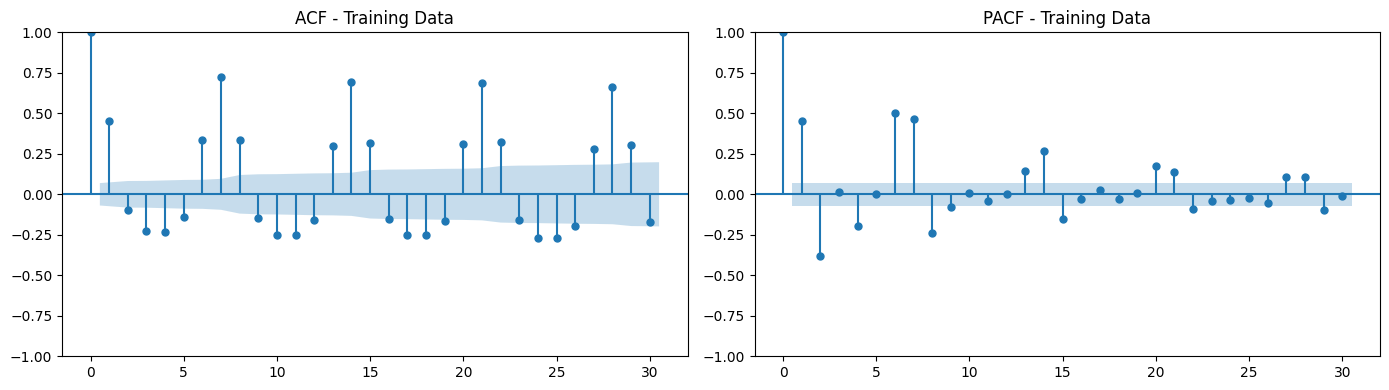

In [546]:
# Plot ACF and PACF

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(train.dropna(), lags=30, ax=axes[0])
plot_pacf(train.dropna(), lags=30, ax=axes[1], method='ywm')

axes[0].set_title('ACF - Training Data')
axes[1].set_title('PACF - Training Data')

plt.tight_layout()
plt.show()

In [547]:
# Train an initial ARIMA model

from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(
    train,
    order=(1, 1, 1)
)

arima_result = arima_model.fit()

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:         traffic_volume   No. Observations:                  803
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -6092.874
Date:                Fri, 23 Oct 2026   AIC                          12191.747
Time:                        13:05:06   BIC                          12205.808
Sample:                    01-01-2016   HQIC                         12197.148
                         - 03-13-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4621      0.027     17.094      0.000       0.409       0.515
ma.L1         -0.9995      0.011    -92.750      0.000      -1.021      -0.978
sigma2      2.303e+05   1.11e+04     20.816      0.0

In [548]:
# Forecast traffic volume for the test period

arima_forecast = arima_result.forecast(
    steps=len(test)
)

arima_forecast.index = test.index

print("Forecast observations:", len(arima_forecast))

display(arima_forecast.head())

Forecast observations: 201


date_time
2018-03-14    3469.994589
2018-03-15    3367.737923
2018-03-16    3320.487295
2018-03-17    3298.653786
2018-03-18    3288.564986
Freq: D, Name: predicted_mean, dtype: float64

In [549]:
# Compare ARIMA models with and without differencing

arima_d0_model = ARIMA(train, order=(1, 0, 1))

# Train the model
arima_d0_result = arima_d0_model.fit()

In [564]:
# Evaluate ARIMA(1,0,1)

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Generate forecast
arima_d0_forecast = arima_d0_result.forecast(steps=len(test))
# Calculate MAE

arima_d0_mae = mean_absolute_error(test, arima_d0_forecast)
# Calculate RMSE

arima_d0_rmse = np.sqrt(mean_squared_error(test, arima_d0_forecast))

print("ARIMA(1,0,1) MAE:", round(arima_d0_mae, 2))
print("ARIMA(1,0,1) RMSE:", round(arima_d0_rmse, 2))

ARIMA(1,0,1) MAE: 479.03
ARIMA(1,0,1) RMSE: 550.36


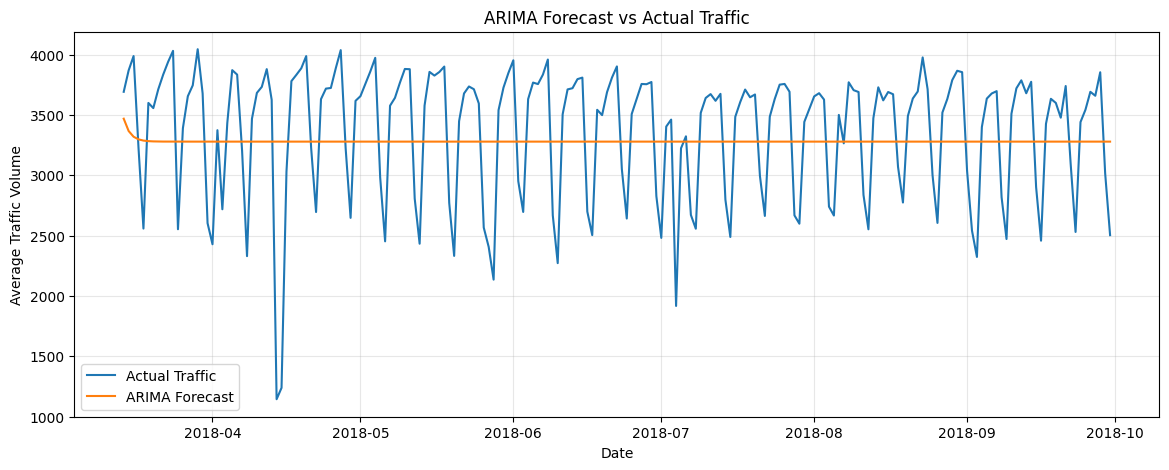

In [551]:
# Compare actual and predicted traffic volume

plt.figure(figsize=(14, 5))

plt.plot(test, label='Actual Traffic')
plt.plot(arima_forecast, label='ARIMA Forecast')

plt.title('ARIMA Forecast vs Actual Traffic')
plt.xlabel('Date')
plt.ylabel('Average Traffic Volume')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [552]:
# Evaluate ARIMA model performance

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

arima_mae = mean_absolute_error(test, arima_forecast)

arima_rmse = np.sqrt(
    mean_squared_error(test, arima_forecast)
)

print("ARIMA MAE:", round(arima_mae, 2))
print("ARIMA RMSE:", round(arima_rmse, 2))

ARIMA MAE: 478.12
ARIMA RMSE: 549.45


In [553]:
# Create a simple baseline forecast

baseline_forecast = np.repeat(
    train.mean(),
    len(test)
)

baseline_mae = mean_absolute_error(
    test,
    baseline_forecast
)

baseline_rmse = np.sqrt(
    mean_squared_error(test, baseline_forecast)
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

Baseline MAE: 479.15
Baseline RMSE: 550.45


In [554]:
# Compare ARIMA with baseline model

arima_comparison = pd.DataFrame({
    'Model': ['Baseline', 'ARIMA(1,1,1)'],
    'MAE': [baseline_mae, arima_mae],
    'RMSE': [baseline_rmse, arima_rmse]
})

display(arima_comparison.round(2))

,Model,MAE,RMSE
0,Baseline,479.15,550.45
1,"ARIMA(1,1,1)",478.12,549.45


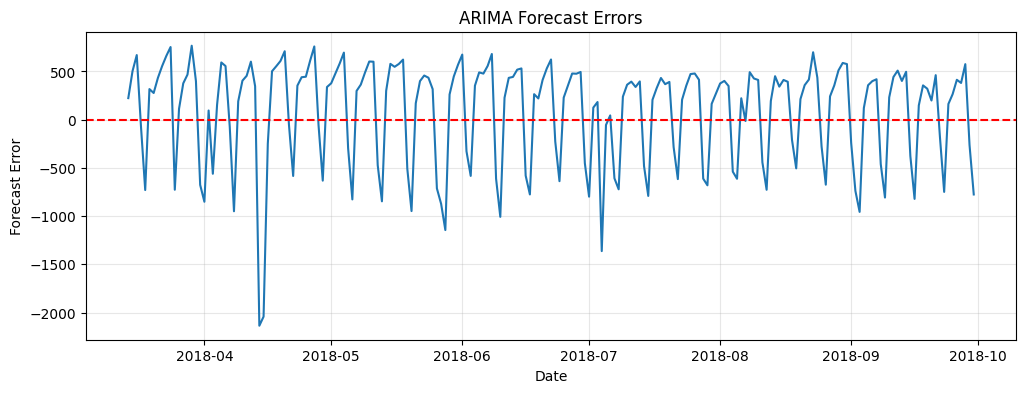

In [555]:
# Analyse ARIMA forecast errors

arima_errors = test - arima_forecast

plt.figure(figsize=(12, 4))

plt.plot(arima_errors)

plt.axhline(0, color='red', linestyle='--')

plt.title('ARIMA Forecast Errors')
plt.xlabel('Date')
plt.ylabel('Forecast Error')

plt.grid(alpha=0.3)
plt.show()

### 7.1 ARIMA Model Evaluation

I tested an ARIMA(1,1,1) model to forecast daily traffic volume.

The model achieved an MAE of 478.12 and an RMSE of 549.45.

I compared these results with a simple baseline model, which achieved an MAE of 479.15 and an RMSE of 550.45.

ARIMA performed slightly better, but the difference was very small.

This suggests that the initial ARIMA model did not capture the traffic patterns very well.

A seasonal model, such as SARIMA, may improve the predictions.

In [556]:
# Final ARIMA evaluation summary

print("ARIMA Model: (1,1,1)")
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nModel performance:")
print("ARIMA MAE:", round(arima_mae, 2))
print("ARIMA RMSE:", round(arima_rmse, 2))

print("\nBaseline performance:")
print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))

print("\nMAE improvement (%):",
      round((baseline_mae - arima_mae) / baseline_mae * 100, 2))

ARIMA Model: (1,1,1)
Training observations: 803
Testing observations: 201

Model performance:
ARIMA MAE: 478.12
ARIMA RMSE: 549.45

Baseline performance:
Baseline MAE: 479.15
Baseline RMSE: 550.45

MAE improvement (%): 0.21


## 8. SARIMA Forecasting

In this section, I will use a SARIMA model to forecast daily traffic volume.

SARIMA is similar to ARIMA, but it also considers seasonal patterns.

Since the dataset contains daily observations, I will investigate weekly seasonality.

In [557]:
# Calculate average traffic volume by day of the week

weekly_pattern = train.groupby(
    train.index.dayofweek
).mean()

weekly_pattern.index = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
]

print(weekly_pattern.round(2))

Monday       3274.96
Tuesday      3511.93
Wednesday    3563.67
Thursday     3654.81
Friday       3658.25
Saturday     2854.18
Sunday       2456.08
Name: traffic_volume, dtype: float64


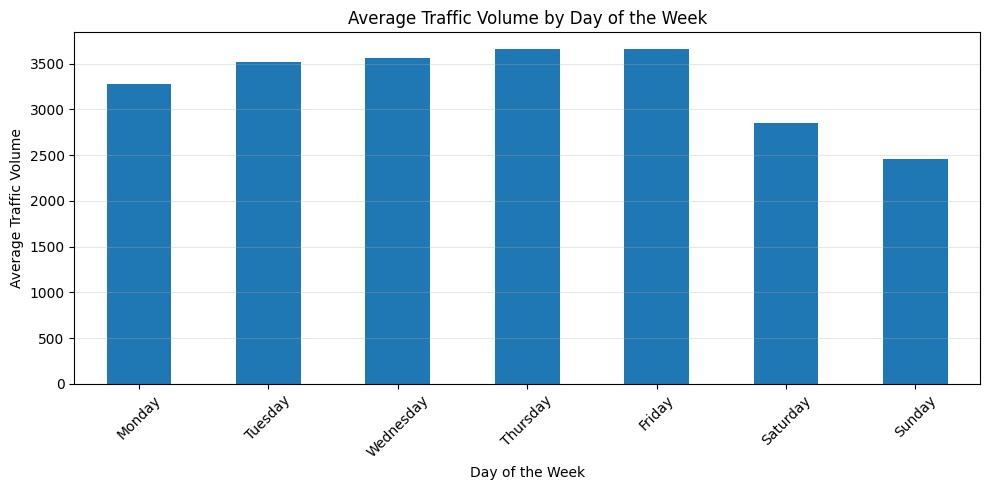

In [558]:
# Visualise average traffic volume by weekday

plt.figure(figsize=(10, 5))

weekly_pattern.plot(kind='bar')

plt.title('Average Traffic Volume by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Traffic Volume')

plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [559]:
# Train SARIMA with weekly seasonality

from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 0, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(
    disp=False,
    maxiter=100
)

print(sarima_result.summary())

                                     SARIMAX Results                                      
Dep. Variable:                     traffic_volume   No. Observations:                  803
Model:             SARIMAX(1, 1, 1)x(1, 0, [], 7)   Log Likelihood               -5722.586
Date:                            Fri, 23 Oct 2026   AIC                          11453.172
Time:                                    13:05:08   BIC                          11471.880
Sample:                                01-01-2016   HQIC                         11460.362
                                     - 03-13-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4301      0.026     16.376      0.000       0.379       0.482
ma.L1         -1.0000      2.194   

In [560]:
# Forecast traffic volume using SARIMA

sarima_forecast = sarima_result.forecast(
    steps=len(test)
)

sarima_forecast.index = test.index

print("Forecast observations:", len(sarima_forecast))

display(sarima_forecast.head())

Forecast observations: 201


date_time
2018-03-14    3772.716937
2018-03-15    3783.418420
2018-03-16    3812.426908
2018-03-17    3333.473683
2018-03-18    2718.194000
Freq: D, Name: predicted_mean, dtype: float64

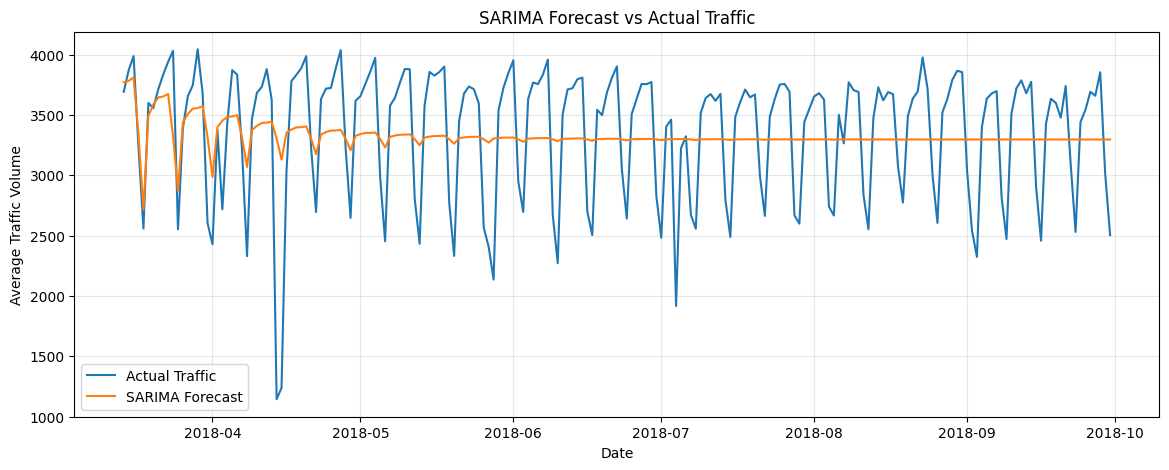

In [561]:
# Compare SARIMA predictions with actual traffic

plt.figure(figsize=(14, 5))

plt.plot(test, label='Actual Traffic')
plt.plot(sarima_forecast, label='SARIMA Forecast')

plt.title('SARIMA Forecast vs Actual Traffic')
plt.xlabel('Date')
plt.ylabel('Average Traffic Volume')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [562]:
# Evaluate SARIMA model performance

sarima_mae = mean_absolute_error(
    test,
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_forecast)
)

print("SARIMA MAE:", round(sarima_mae, 2))
print("SARIMA RMSE:", round(sarima_rmse, 2))

SARIMA MAE: 430.99
SARIMA RMSE: 512.07


In [563]:
# Compare forecasting models

forecast_comparison = pd.DataFrame({
    'Model': [
        'Baseline',
        'ARIMA(1,1,1)',
        'SARIMA(1,1,1)(1,0,0,7)'
    ],
    'MAE': [
        baseline_mae,
        arima_mae,
        sarima_mae
    ],
    'RMSE': [
        baseline_rmse,
        arima_rmse,
        sarima_rmse
    ]
})

display(forecast_comparison.round(2))

,Model,MAE,RMSE
0,Baseline,479.15,550.45
1,"ARIMA(1,1,1)",478.12,549.45
2,"SARIMA(1,1,1)(1,0,0,7)",430.99,512.07


### 8.1 SARIMA Model Evaluation

I tested a SARIMA model with a weekly seasonal period of seven days.

The model was evaluated using the same testing data as ARIMA.

I compared the MAE and RMSE results to understand whether
including weekly seasonality improved the predictions.

The results are presented in the comparison table above.